# 0. Setup, Data and Reproducibility

In [17]:
%load_ext autoreload
%autoreload 2    

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Rebuild the working set and the three CV fold sets

In [18]:
import sys
from pathlib import Path
from collections import Counter
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
from part1 import experiment as p1_experiment      # has cross_validation_split
from datasets import load_dataset
import project2_lib as P2

snli = load_dataset("stanfordnlp/snli")

train_pairs_all, stats = P2.clean_training_pool(snli["train"])
print(stats)
working_set = P2.build_working_set(train_pairs_all)
print("working set:", len(working_set),
      dict(sorted(Counter(l for _, l in working_set).items())))

cv_sets = {s: p1_experiment.cross_validation_split(working_set, k=P2.NUM_FOLDS, seed=s)
           for s in P2.CV_SEEDS}

{'base_pool': 549325, 'dropped_one_word': 42, 'dropped_conflict': 92, 'final_pool': 549191}
working set: 40000 {0: 13355, 1: 13306, 2: 13339}


### Verify the rebuild reproduces a Project 1 result

In [19]:
import pickle
GRID_CKPT = root / "part1" / "results" / "grid_checkpoint.pkl" # TODO remember i need to adjust
with open(GRID_CKPT, "rb") as f:
    grid = pickle.load(f)

for key in ["mlp1_indicator", "logistic_indicator"]:   # one neural, one linear
    r = P2.verify_against_grid(grid, p1_experiment.cross_validation_split, working_set, key)
    print(f"{key:20s} cm_acc={r['cm_acc']:.4f}  grid_acc={r['grid_acc']:.4f}  match={r['match']}  n={r['n']}")
    assert r["match"], f"{key}: rebuild does NOT match the grid — reconcile before training"

mlp1_indicator       cm_acc=0.5826  grid_acc=0.5826  match=True  n=120000
logistic_indicator   cm_acc=0.5750  grid_acc=0.5750  match=True  n=120000


### Clean the dev and test splits

In [20]:
val_pairs  = P2.clean_eval_split(snli["validation"])
test_pairs = P2.clean_eval_split(snli["test"])
print("dev:", len(val_pairs), " test:", len(test_pairs))

dev: 9842  test: 9824


### Token-id cache

In [21]:
import part2, project2_lib as P2

emb_model = part2.clslib.PretrainedEmbeddings("glove6B/glove.6B.300d.txt", num_dims=300)  # ~1-2 min
base_tok  = part2.clslib.BasicTokenizer(lowercase=True, remove_punct=False,
             remove_stopwords=False, language="english", vocab=emb_model.vocab)

sents    = P2.sentences_in(working_set, val_pairs, test_pairs)
id_cache = P2.build_id_cache(sents, base_tok)       # one tokenization per unique sentence
tok      = P2.CachedTokenizer(id_cache, base_tok)   # drop-in tokenizer for the training loop
print("emb vocab:", len(emb_model.vocab), "| cached sentences:", f"{len(id_cache):,}")

emb vocab: 400002 | cached sentences: 97,713


### Seeding, logging and checkpoints


In [22]:
P2.set_all_seeds(P2.run_seed(cv_seed=0, fold=0))     # == seed 0
ck = P2.Checkpoint("results/grid_p2.pkl")
print("checkpoint resumes with:", ck.keys())
with P2.Timer() as t:
    _ = sum(range(5_000_000))
print("timer:", round(t.sec, 3), "s")

checkpoint resumes with: []
timer: 0.115 s


### Timing probe

In [50]:
cfgs = {"pool_mean": ({"type":"pool","pool":"mean","freeze":True}, "nli"),
        "lstm_last": ({"type":"rnn","cell":"lstm","hidden":128,"freeze":True}, "nli")}
for name, (enc, combo) in cfgs.items():
    P2.set_all_seeds(P2.run_seed(0, 0))
    with P2.Timer() as t:
        PP.train(fold0["training"], fold0["validation"], tok, emb_model, enc, combo, head, opt, 3, device)
    print(f"{name}: {t.sec:.1f}s / 10 epochs on one fold  ->  ~{t.sec*5/60:.1f} min per 5-fold screen")

NameError: name 'head' is not defined

# 1. Choose the embedding model

The decision rule:

- Primary metric: hypothesis-side token coverage on the working set. Token coverage (not type coverage) because it measures how much of the running signal is a real vector rather than the mean/unknown vector that embed-and-pool falls back to. Hypothesis side because hypotheses are crowd-written (the weaker, typo-prone side) and the side the label leaks into so it’s the side where coverage actually bites.
- Rule: pick the 300d candidate with the highest hypothesis-side token coverage.
- Tie-break (within 0.5 pp): prefer GloVe 2024 wikigiga, because it ships at 50/100/200/300d from one corpus (a clean embedding-size ablation for Step 4), it’s uncased (matching our lowercased tokenizer), and its 1.2M-vocab matrix is far lighter to load than 840B’s 2.2M.
- Recorded either way: the coverage numbers, the OOV breakdown, and the tokenizer probe, so the justification is evidence.

Three criteria sit alongside coverage as discussion: tokenization coherence (the probe), domain fit (840B is web-trained, wikigiga is Wikipedia + newswire, SNLI premises are Flickr captions), and literature comparability (Bowman and InferSent both used 840B).


### Downloads


In [27]:
import urllib.request
url = "https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download"
urllib.request.urlretrieve(url, "glove.2024.wikigiga.50d.zip")
print("done")

done


In [28]:
# fastText wiki-news
import urllib.request
urllib.request.urlretrieve(
    "https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip",
    "wiki-news-300d-1M.vec.zip")
print("fasttext done")

fasttext done


In [29]:
# 840B (2 GB) 
import urllib.request
urllib.request.urlretrieve(
    "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.840B.300d.zip",
    "glove.840B.300d.zip")
print("840B done")

840B done


### Read the three vocabularies (no matrix loaded)

In [30]:
import step1_embeddings as S
vocabs = {
    "glove_wikigiga": S.read_embedding_vocab("glove.2024.wikigiga.50d.zip", 50),
    "glove_840B":     S.read_embedding_vocab("glove.840B.300d.zip", 300),           # or path_840b
    "fasttext_wiki":  S.read_embedding_vocab("wiki-news-300d-1M.vec.zip", 300, skip_first_line=True),
}
for k, v in vocabs.items():
    print(f"{k:16s} usable vocab (lowercased, deduped): {len(v):,}")

glove_wikigiga   usable vocab (lowercased, deduped): 1,287,614
glove_840B       usable vocab (lowercased, deduped): 1,702,820
fasttext_wiki    usable vocab (lowercased, deduped): 830,461


### Tokenize once, then the coverage table

In [31]:
import nltk; nltk.download("punkt"); nltk.download("punkt_tab")
import part2, project2_lib as P2, pandas as pd

keep_tok = part2.clslib.BasicTokenizer(lowercase=True, remove_punct=False,
            remove_stopwords=False, language="english", vocab=None)

sents  = P2.sentences_in(working_set, val_pairs, test_pairs)
tcache = S.build_token_cache(sents, keep_tok)        # candidate-independent

splits = {"work": working_set, "dev": val_pairs, "test": test_pairs}
df = pd.DataFrame(S.coverage_table(splits, tcache, vocabs))
print(df[df.side == "hypothesis"].pivot(index="embedding", columns="split", values="token_cov"))
df

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


split              dev    test    work
embedding                             
fasttext_wiki   0.9985  0.9981  0.9983
glove_840B      0.9994  0.9994  0.9993
glove_wikigiga  0.9981  0.9980  0.9979


,embedding,split,side,token_cov,type_cov,n_tokens,oov_tokens
0,glove_wikigiga,work,premise,0.9958,0.9320,561556,2372
1,glove_wikigiga,work,hypothesis,0.9979,0.9468,330735,693
2,glove_wikigiga,work,both,0.9966,0.9180,892291,3065
3,glove_wikigiga,dev,premise,0.9951,0.9675,149453,729
4,glove_wikigiga,dev,hypothesis,0.9981,0.9753,82212,155
5,glove_wikigiga,dev,both,0.9962,0.9628,231665,884
6,glove_wikigiga,test,premise,0.9947,0.9637,148880,783
7,glove_wikigiga,test,hypothesis,0.9980,0.9750,81704,162
8,glove_wikigiga,test,both,0.9959,0.9615,230584,945
9,glove_840B,work,premise,0.9992,0.9746,561556,475


OOV inspection

In [32]:
for name, v in vocabs.items():
    o = S.top_oov(working_set, tcache, v, side="hypothesis", k=30)
    print(f"\n== {name}  ({o['n_oov_types']} OOV types)  categories={o['by_category']}")
    print("   ", [t for t, _ in o["top"][:15]])


== glove_wikigiga  (557 OOV types)  categories={'alpha': 330, 'nonalpha': 220, 'numeric': 7}
    ['t-shirt', 't-shirts', 'dark-haired', 'middle-aged', 'blond-hair', 'red-haired', 'black-haired', 'world-famous', '..', 'african-american', 'dark-skinned', 'short-haired', 'empty-handed', 'yo-yo', 'go-cart']

== glove_840B  (233 OOV types)  categories={'alpha': 178, 'nonalpha': 53, 'numeric': 2}
    ['blond-hair', '..', 'parasailer', 'mo-hawk', 'rollerskaters', 'rollerskater', 'shoeshiner', 'pnacho', 'drunning', 'midkick', 'pointign', 'trick-o-treating', 'skateboaing', 'suicice', 'wearinh']

== fasttext_wiki  (392 OOV types)  categories={'alpha': 322, 'nonalpha': 66, 'numeric': 4}
    ["n't", '``', "''", 'blond-hair', 'parasailer', 'bvoy', 'sitted', 'perfoms', 'backstrokes', 'rollerskaters', 'weaing', 'rollerskater', 'mo-hawk', 'waveing', 'competititon']


### Tokenizer-coherence probe

In [33]:
examples = ["A girl isn't playing.", "The children's toys are on the table.",
            "a well-dressed woman", "Two people and 3 dogs.", "Someone is outdoors."]
for name, v in vocabs.items():
    print("==", name)
    for r in S.tokenizer_probe(keep_tok, v, examples):
        print("   ", r["tokens"], " OOV:", r["oov"])

== glove_wikigiga
    ['a', 'girl', 'is', "n't", 'playing', '.']  OOV: []
    ['the', 'children', "'s", 'toys', 'are', 'on', 'the', 'table', '.']  OOV: []
    ['a', 'well-dressed', 'woman']  OOV: ['well-dressed']
    ['two', 'people', 'and', '3', 'dogs', '.']  OOV: []
    ['someone', 'is', 'outdoors', '.']  OOV: []
== glove_840B
    ['a', 'girl', 'is', "n't", 'playing', '.']  OOV: []
    ['the', 'children', "'s", 'toys', 'are', 'on', 'the', 'table', '.']  OOV: []
    ['a', 'well-dressed', 'woman']  OOV: []
    ['two', 'people', 'and', '3', 'dogs', '.']  OOV: []
    ['someone', 'is', 'outdoors', '.']  OOV: []
== fasttext_wiki
    ['a', 'girl', 'is', "n't", 'playing', '.']  OOV: ["n't"]
    ['the', 'children', "'s", 'toys', 'are', 'on', 'the', 'table', '.']  OOV: []
    ['a', 'well-dressed', 'woman']  OOV: []
    ['two', 'people', 'and', '3', 'dogs', '.']  OOV: []
    ['someone', 'is', 'outdoors', '.']  OOV: []


### Confirm the cue words have vectors

In [34]:
ARTIFACT_WORDS = ["not","no","never","nobody","nothing","animal","outdoors","outside",
                  "instrument","person","people","tall","first","sad","happy"]
for name, v in vocabs.items():
    print(f"{name:16s} missing cue words: {[w for w in ARTIFACT_WORDS if w not in v]}")

glove_wikigiga   missing cue words: []
glove_840B       missing cue words: []
fasttext_wiki    missing cue words: []


### why we keep stopwords

In [35]:
nltk.download("stopwords")
from nltk.corpus import stopwords
stop = set(stopwords.words("english"))
strip_tok = part2.clslib.BasicTokenizer(lowercase=True, remove_punct=True,
             remove_stopwords=True, language="english", vocab=None)

rep = S.stopword_report(working_set, tcache, stop, strip_tok)
import json; print(json.dumps(rep["cue_is_stopword"], indent=2))
print("empty after strip:", rep["empty_after_strip"], "/", rep["total_sentences"])
neg = S.CUE_GROUPS["negation"]
print("per-negation-cue hypothesis counts:",
      {w: rep["cue_hypothesis_counts"][w] for w in neg})

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


{
  "negation": {
    "not": true,
    "no": true,
    "nor": true,
    "never": false,
    "nobody": false,
    "nothing": false,
    "none": false,
    "without": false,
    "cannot": false,
    "n't": false
  },
  "quantifier": {
    "all": true,
    "some": true,
    "any": true,
    "every": false,
    "most": true,
    "few": true,
    "both": true,
    "each": true
  },
  "spatial_prep": {
    "in": true,
    "on": true,
    "outside": false,
    "inside": false,
    "near": false,
    "behind": false,
    "under": true,
    "over": true
  }
}
empty after strip: 1 / 80000
per-negation-cue hypothesis counts: {'not': 311, 'no': 226, 'nor': 0, 'never': 18, 'nobody': 189, 'nothing': 37, 'none': 6, 'without': 32, 'cannot': 0, "n't": 101}


Line of thinking: NLTK’s list contains not/no/nor but not never/nobody/nothing, so stripping stopwords deletes the negation from exactly the hypotheses that carry those three which we multiply by their hypothesis counts to get the number of examples that would lose their contradiction signal, plus the empty_after_strip count of sentences that would collapse to all-unknown (which also crashes the LSTM). Thats what justifies keeping stopwords.

In [ ]:
import urllib.request, zipfile
urllib.request.urlretrieve("https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip", "glove.6B.zip")
with zipfile.ZipFile("glove.6B.zip") as z:
    z.extractall("glove6B")        # -> glove6B/glove.6B.{50,100,200,300}d.txt
print(zipfile.ZipFile("glove.6B.zip").namelist())

['glove.6B.100d.txt', 'glove.6B.200d.txt', 'glove.6B.300d.txt', 'glove.6B.50d.txt']


In [36]:
import step1_embeddings as S, pandas as pd
v6b = S.read_embedding_vocab("glove6B/glove.6B.300d.txt", 300)   # vocab same across dims
print("glove_6B usable vocab:", f"{len(v6b):,}")

rows = S.coverage_table({"work": working_set, "dev": val_pairs, "test": test_pairs},
                        tcache, {"glove_6B": v6b})
print(pd.DataFrame(rows)[lambda d: d.side == "hypothesis"][["split","token_cov","type_cov","oov_tokens"]])

glove_6B usable vocab: 400,001
  split  token_cov  type_cov  oov_tokens
1  work     0.9977    0.9371         748
4   dev     0.9980    0.9709         163
7  test     0.9977    0.9684         186


### Decision:

- Deploy GloVe 6B, 300d (Wikipedia 2014 + Gigaword 5, uncased). Hypothesis-side token coverage on the working set is tied across every candidate (840B 0.9993, fastText 0.9983, wikigiga-2024 0.9979, 6B 0.9977 — a 0.16 pp spread, below downstream noise), so coverage does not discriminate and the pre-registered tie-break decides on the Wikipedia+Gigaword family: uncased (matching our lowercased tokenizer) and a clean 50/100/200/300d size ablation from one corpus. wikigiga-2024 was the first choice, but with Stanford's host down and no raw-text mirror (the Hugging Face copies are a repackaged binary and a txtai sqlite, which the loader cannot read), we deploy 6B: same corpus family, uncased. 840B stays the Step 4 runner-up swap, so the choice is confirmed on task accuracy. 
- 840B leads on every cell, most of all type coverage, driven by hyphenated appearance compounds (dark-haired, middle-aged, well-dressed) that 6B and wikigiga split. That is partly a tokenization artifact since splitting on hyphens puts both pieces in wikigiga so we add a hyphen-splitting variant as an ablation, and keep 840B as the Step 4 runner-up swap so the choice is confirmed on task accuracy, not on the coverage proxy.
- Stopwords and punctuation are kept. Stripping stopwords would delete the negation cue from hypotheses using not (311) and no (226); nobody (189), nothing (37), never (18), without (32) and n't (101) are not stopwords and survive. Emptying risk is 1/80000. fastText has no n't vector, sending 101 hypotheses to unknown which one more reason for GloVe over fastText beyond coverage.

# Explore what the embeddings capture

Predictions: 

Each diagnostic exists to confirm or break one of these:

- Antonyms and co-hyponyms sit nearly as close as synonyms. Distributional training can’t separate “near-opposites that share contexts” (hot/cold, dog/cat) from true synonyms. This is the limitation that should worry us most, because contradiction often turns on exactly one swapped word.
- Cosine alone can’t separate the relations, but the [u,v,|u−v|,u·v] probe can. This is the argument for why we need a learned combination rule in Steps 3–5, not raw similarity and it mirrors the tutorial’s sentiment result where clustering failed and a linear probe succeeded.
- Sentence-level geometry separates entailment from {neutral, contradiction} better than it separates neutral from contradiction. Raw overlap signals “related topics,” which is most of entailment, but can’t tell apart a neutral elaboration from a contradiction.
- 6B and 840B give similar probe scores. This is the task-specific evidence that our embedding choice doesn’t cost us versus the literature-standard alternative.

In [37]:
import step2_explore as E, pandas as pd, matplotlib.pyplot as plt
import nltk; nltk.download("wordnet"); nltk.download("omw-1.4")
from nltk.corpus import stopwords
stop = set(stopwords.words("english"))

snli_words = set().union(*tcache.values())                       # all SNLI tokens (from Step 1 cache)
content_words = E.frequent_content_words(working_set, tcache, emb_model, stop, n=3000)
nidx = E.NeighbourIndex(emb_model, restrict_words=snli_words)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...


### Neighbours of cue words.

In [38]:
cue = ["man","woman","dog","cat","running","sitting","happy","sad","big","small",
       "open","closed","not","outdoors","sleeping","standing","child","red","empty","tall"]
for w in cue:
    print(f"{w:10s}", [f"{n}:{c:.2f}" for n, c in nidx.neighbours(w, k=6)])

man        ['woman:0.70', 'person:0.64', 'boy:0.62', 'he:0.59', 'men:0.58', 'himself:0.58']
woman      ['girl:0.73', 'man:0.70', 'mother:0.69', 'she:0.64', 'her:0.63', 'female:0.63']
dog        ['dogs:0.79', 'cat:0.68', 'pet:0.63', 'puppy:0.59', 'hound:0.55', 'horse:0.54']
cat        ['dog:0.68', 'cats:0.68', 'pet:0.59', 'dogs:0.54', 'feline:0.49', 'monkey:0.49']
running    ['ran:0.75', 'run:0.70', 'line:0.52', 'going:0.52', 'out:0.51', 'back:0.51']
sitting    ['sit:0.72', 'sat:0.72', 'beside:0.66', 'standing:0.64', 'sits:0.62', 'seated:0.59']
happy      ["'m:0.71", 'glad:0.69', 'really:0.66', 'always:0.65', 'everyone:0.64', 'everybody:0.63']
sad        ['sorry:0.61', 'happy:0.57', 'unfortunate:0.55', 'awful:0.54', 'horrible:0.53', 'terrible:0.51']
big        ['bigger:0.70', 'huge:0.70', 'biggest:0.65', 'like:0.62', "n't:0.60", 'large:0.59']
small      ['large:0.79', 'tiny:0.73', 'smaller:0.71', 'larger:0.66', 'few:0.61', 'sized:0.60']
open       ['opening:0.57', 'round:0.56', 'opens:0

### Cosine by relation

{'synonym': 500, 'hypernym': 500, 'antonym': 500, 'co_hyponym': 500, 'random': 500}
     relation    n  mean_cos  median_cos     std
0     synonym  500    0.3267      0.2915  0.2193
1    hypernym  500    0.2314      0.2161  0.1541
2     antonym  500    0.3364      0.3331  0.1874
3  co_hyponym  500    0.2086      0.2014  0.1588
4      random  500    0.0983      0.0949  0.1137


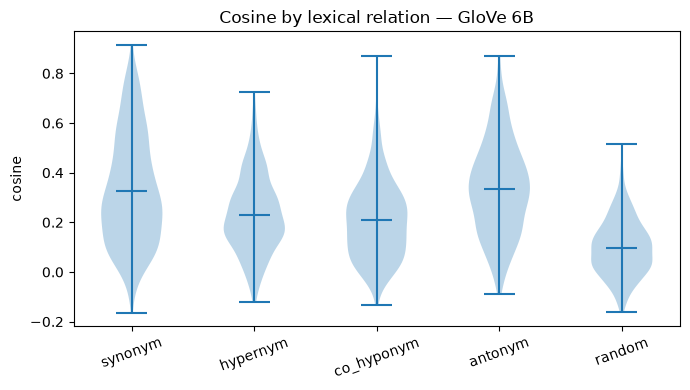

In [39]:
snli_for_pairs = snli_words & vocabs["glove_840B"]        # words both embeddings have
pairs_by_rel = E.build_relation_pairs(content_words, emb_model, snli_for_pairs,
                                      max_per_relation=500, per_word_cap=5, seed=0)
print({k: len(v) for k, v in pairs_by_rel.items()})

cbr = E.cosine_by_relation(pairs_by_rel, emb_model)
print(pd.DataFrame(E.summarize_relations(cbr)))

order = [r for r in ["synonym","hypernym","co_hyponym","antonym","random"] if r in cbr]
plt.figure(figsize=(7,4))
plt.violinplot([cbr[r] for r in order], showmeans=True)
plt.xticks(range(1, len(order)+1), order, rotation=20); plt.ylabel("cosine")
plt.title("Cosine by lexical relation — GloVe 6B"); plt.tight_layout(); plt.show()

### The relation probe

In [40]:
Xf, Xc, y, pw, rels = E.build_probe_dataset(pairs_by_rel, emb_model)
tr, te, dropped = E.word_group_split(pw, seed=0, test_frac=0.3)
print("relations:", rels, "| train", len(tr), "test", len(te), "| dropped cross-word pairs", dropped)

print("6B   full  [u,v,|u-v|,u*v]:", E.run_probe(Xf, y, tr, te))
print("6B   cosine-only baseline :", E.run_probe(Xc, y, tr, te))

# runner-up 840B, loaded only for the pair-words (seconds, not a 2 GB load)
pair_words = sorted({w for p in pw for w in p})
emb840 = E.load_subset_embeddings("glove.840B.300d.zip", pair_words, num_dims=300)
Xf8, Xc8, y8, pw8, _ = E.build_probe_dataset(pairs_by_rel, emb840)
print("840B full                 :", E.run_probe(Xf8, y8, tr, te))   # same split indices

relations: ['antonym', 'co_hyponym', 'hypernym', 'random', 'synonym'] | train 1199 test 247 | dropped cross-word pairs 1054
6B   full  [u,v,|u-v|,u*v]: {'accuracy': 0.3968, 'macro_f1': 0.3939, 'confusion': array([[26,  5, 10,  5,  7],
       [ 5, 19,  8,  2,  5],
       [10,  9,  8, 22, 13],
       [ 3,  6,  5, 29,  2],
       [ 6,  9,  8,  9, 16]])}
6B   cosine-only baseline : {'accuracy': 0.3239, 'macro_f1': 0.2439, 'confusion': array([[ 0,  9,  0, 10, 34],
       [ 0, 12,  0, 14, 13],
       [ 0, 19,  0, 18, 25],
       [ 0,  6,  0, 39,  0],
       [ 0, 10,  0,  9, 29]])}
840B full                 : {'accuracy': 0.3968, 'macro_f1': 0.3935, 'confusion': array([[31,  4, 10,  3,  5],
       [ 3, 12,  8,  8,  8],
       [ 4, 16, 18, 17,  7],
       [ 4,  9,  7, 22,  3],
       [ 9,  9, 10,  5, 15]])}


### Sentence-level geometry by gold label

entail: cosine=0.822  soft-overlap=0.829  (n=13355)
neutral: cosine=0.784  soft-overlap=0.746  (n=13306)
contra: cosine=0.762  soft-overlap=0.720  (n=13339)


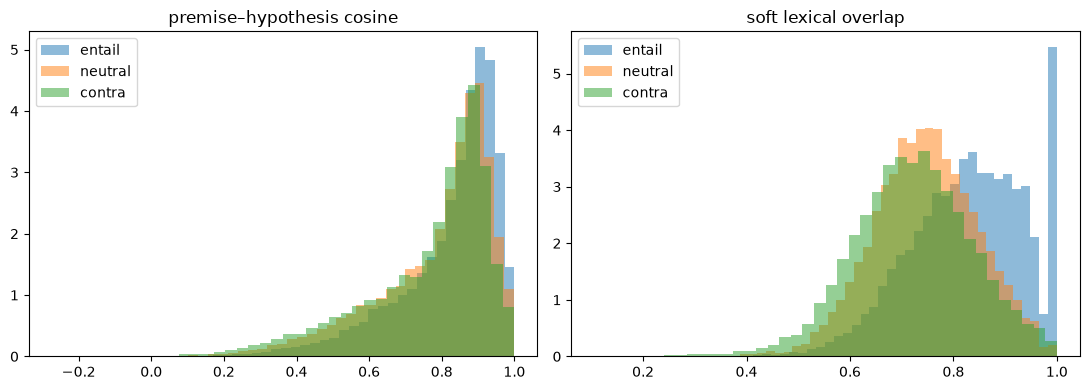

In [41]:
cos_by, soft_by = E.sentence_diagnostics(working_set, tcache, emb_model)
for lab, name in [(0,"entail"), (1,"neutral"), (2,"contra")]:
    print(f"{name}: cosine={cos_by[lab].mean():.3f}  soft-overlap={soft_by[lab].mean():.3f}  (n={len(cos_by[lab])})")

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for lab, name in [(0,"entail"), (1,"neutral"), (2,"contra")]:
    ax[0].hist(cos_by[lab], bins=40, alpha=0.5, density=True, label=name)
    ax[1].hist(soft_by[lab], bins=40, alpha=0.5, density=True, label=name)
ax[0].set_title("premise–hypothesis cosine"); ax[1].set_title("soft lexical overlap")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

### Gender-bias projection

In [42]:
g = E.gender_direction(emb_model)
words = ["cooking","cleaning","nursing","shopping","dancing","teaching","driving",
         "building","fighting","working","coaching","beautiful","strong","gentle"]
proj = E.project_on_direction(words, g, emb_model)
print("most she-leaning:", [(w, round(s,3)) for w, s in proj[:5]])
print("most he-leaning :", [(w, round(s,3)) for w, s in proj[-5:]])

most she-leaning: [('beautiful', -0.236), ('nursing', -0.154), ('dancing', -0.139), ('cooking', -0.134), ('shopping', -0.086)]
most he-leaning : [('driving', 0.044), ('gentle', 0.045), ('building', 0.046), ('coaching', 0.078), ('fighting', 0.1)]


### Prediction scorecard

- Antonyms ≈ synonyms: confirmed. Co-hyponyms: refined.
Antonyms (mean cosine 0.326) are tied with synonyms (0.329), and their median is actually higher (0.328 vs 0.293). The neighbour lists make it clear: small→large 0.79, outdoors→indoors 0.70, empty→filled 0.68, closed→opened 0.64, sad→happy 0.57 so antonyms are routinely the nearest neighbour. That’s the headline limitation for NLI, because contradiction usually hinges on one swapped word the geometry treats as a near-synonym. But co-hyponyms (0.205) sit lower, near hypernym level therefore clearly separable from synonyms. So the prediction holds for antonyms, not for co-hyponyms. 

- Cosine can’t separate relations, the probe can: confirmed in direction, modest in size.
Cosine-only collapses the problem: it separates random (unrelated → low cosine) but lumps synonym/antonym/hypernym/co-hyponym together so it never predicts hypernym and even labels synonyms as antonyms (macro-F1 0.264). The full [u,v,|u−v|,u·v] probe recovers structure (hypernym becomes predictable, macro-F1 0.332). But even the full probe only reaches ~33% on 5 balanced classes (chance 20%), so relation-typing from static vectors is hard. That weakness is itself the point: static embeddings carry “relatedness,” not “relation,” and a learned transform only partly fixes it which is the argument for a trained compositional encoder further in the pipeline.

- Sentence geometry separates entailment but not neutral-vs-contradiction: confirmed.
Soft overlap orders entail 0.829 > neutral 0.746 > contra 0.720, and the histogram shows entailment with a spike at overlap ≈ 1.0 with hypotheses that are near-copies of the premise. Neutral and contradiction sit almost on top of each other. So raw overlap handles the easy half of SNLI and is blind to the hard half, exactly as predicted. 

- 6B ≈ 840B: confirmed.
Full-probe macro-F1 0.332 (6B) vs 0.322 (840B) —> indistinguishable, 840B even fractionally lower.  

- Bias: beautiful/nursing/cooking/shopping/dancing lean female, fighting/coaching/building/driving lean male which is the expected stereotype pattern, though magnitudes are small (±0.2) and a couple (gentle) are near-zero noise. Enough to state the bias is present, consistent with Bolukbasi, and amplified by SNLI’s elicitation per Rudinger.

Essentially:

Static embeddings know what words are about but not how they relate so they rate antonyms as similar as synonyms, and raw sentence overlap catches entailment (often a near-copy of the premise) but is blind to the neutral-versus-contradiction distinction. So the signal NLI actually needs has to be learned, not read off the geometry. 

# 3. Build the sentence-pair pipeline

 We encode the premise and the hypothesis with one shared encoder, fuse the two
vectors with a combination rule, and classify with a tutorial-style log-softmax MLP.
This mirrors `part2.experiment` (best epoch by validation loss, same result structure),
so the Project 1 analysis code and our Step 0 seeding / logging / checkpoint drop in unchanged.

**Encoders** (one interface, `enc_dim` + `forward([B,L]) -> [B, enc_dim]`):
- `PoolEncoder` — mean / sum / max pooling (mean & sum match the tutorial numerically)
- `RNNEncoder` — LSTM / GRU, uni- or bi-directional, output = last state or max-over-states, word dropout

**Combination rules:** `concat` = [u, v] · `nli` = [u, v, |u−v|, u·v] · `hypothesis_only` = [v] (ignores the premise)

**Head:** the pooled features are **BatchNorm-normalised** before the MLP. Without this, the
large, uneven norms of raw pooled GloVe vectors saturate the Tanh and the head cannot reach
even a linear probe's accuracy (it stalled ~0.55 with a flat loss). A `StandardScaler + LogisticRegression`
probe diagnosed a usable linear signal (val 0.611) so input BatchNorm is the learnable equivalent.

**Verification (seed 0, fold 0, frozen mean-pool, 15 epochs):**
- 6/6 smoke tests pass: batched == single, hypothesis-only blind to premise, pool order-invariant
  vs RNN order-sensitive, seed reproduces, empty-sequence guard, combination widths.
- After the fix the MLP reaches the linear ceiling: **nli val 0.6111** (= LogReg 0.611), loss 0.895 → 0.863.
- `nli` (0.611) beats `hypothesis_only` (0.585); plain `concat` (0.583) does not — the premise signal
  comes from the `|u−v|` / `u·v` interaction features, not raw concatenation (echoing Project 1).

This ~0.61 frozen mean-pool result is the **baseline** that next step (max-pooling, fine-tuning, more
capacity) builds on.

In [31]:
import project2_pairs as PP
PP.run_smoke_tests(emb_model, device="cpu")

[PASS] batched == single (pool)  max|diff|=0.00e+00
[PASS] hypothesis_only ignores premise  max|diff|=0.00e+00
[PASS] pool order-invariant, RNN order-sensitive  pool_same=True rnn_differs=True
[PASS] seed reproduces model  
[PASS] empty-sequence guard  empty -> [unk]
[PASS] combo feature widths  

6/6 smoke tests passed


{'batched == single (pool)': True,
 'hypothesis_only ignores premise': True,
 'pool order-invariant, RNN order-sensitive': True,
 'seed reproduces model': True,
 'empty-sequence guard': True,
 'combo feature widths': True}

CHECKED! batched equals single, hypothesis-only is blind to the premise, pooling is order-invariant while the RNN isn’t, seeds reproduce, the empty-sequence guard fires, and the combination widths are right.

### One-fold sanity run

In [39]:
import importlib, project2_pairs as PP; importlib.reload(PP)

opt  = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 128, "num_epochs": 15}
head = {"hidden1": 100, "hidden2": 100, "dropout": 0.1}          # input_norm defaults to True now
for combo in ["nli", "concat", "hypothesis_only"]:
    P2.set_all_seeds(P2.run_seed(0, 0))
    met, bp = PP.train(fold0["training"], fold0["validation"], tok, emb_model,
                       {"type":"pool","pool":"mean","freeze":True}, combo, head, opt, 3, device)
    print(f"{combo:16s} best val={met[bp]['val_metrics']['accuracy']:.4f}  "
          f"max={max(e['val_metrics']['accuracy'] for e in met):.4f}  "
          f"loss {met[0]['val_metrics']['loss']:.3f}->{met[bp]['val_metrics']['loss']:.3f}")

nli              best val=0.6111  max=0.6111  loss 0.895->0.863
concat           best val=0.5796  max=0.5830  loss 0.944->0.904
hypothesis_only  best val=0.5849  max=0.5849  loss 0.949->0.895


# 4. Embed-and-pool experiments

We vary one axis at a time from a fixed anchor, screen each value on one seed, and confirm only the winners.

### Build the embeddings and tokenizer variants

In [43]:
import importlib, project2_pairs as PP, project2_sweep as SW, project2_lib as P2
importlib.reload(PP); importlib.reload(SW)
import part2, pandas as pd, torch
device = "cuda" if torch.cuda.is_available() else "cpu"

# embeddings at three dims (6B files share vocab order, so one tokenizer serves all)
emb_models = {300: emb_model}
for dim in (50, 100):
    emb_models[dim] = part2.clslib.PretrainedEmbeddings(f"glove6B/glove.6B.{dim}d.txt", num_dims=dim)
assert emb_models[50].vocab.words[:10] == emb_models[300].vocab.words[:10], "vocab order differs across dims!"

# tokenizer variants, each with its own id-cache
def build_base(remove_stopwords, vocab):
    return part2.clslib.BasicTokenizer(lowercase=True, remove_punct=False,
            remove_stopwords=remove_stopwords, language="english", vocab=vocab)
class HyphenTok:
    def __init__(self, base): self.b = base; self.vocab = base.vocab
    def tokens(self, text):
        out = []
        for t in self.b.tokens(text):
            out.extend(t.split("-") if "-" in t else [t])
        return out
    def ids(self, text): return [self.vocab.index(t) for t in self.tokens(text)]

sents = P2.sentences_in(working_set, val_pairs, test_pairs)
specs_tok = {"keep":   build_base(False, emb_model.vocab),
             "nostop": build_base(True,  emb_model.vocab),
             "hyphen": HyphenTok(build_base(False, emb_model.vocab))}
tok_variants = {k: P2.CachedTokenizer(P2.build_id_cache(sents, bt), bt) for k, bt in specs_tok.items()}
print("embeddings:", sorted(emb_models), "| tokenizers:", list(tok_variants))

embeddings: [50, 100, 300] | tokenizers: ['keep', 'nostop', 'hyphen']


The runner:

In [44]:
RESULTS = "results_p2"
ck = P2.Checkpoint(f"{RESULTS}/sweep_ckpt.pkl")

def run_axis(name, seeds=(0,)):
    specs = SW.axis(name)
    print(f"=== {name}  (seeds {list(seeds)}) ===")
    res = SW.screen(specs, cv_sets, emb_models, tok_variants, ck, RESULTS, list(seeds), device=device)
    anchor = next(l for l in specs if "anchor" in l)
    return res, pd.DataFrame(SW.summarize(res, anchor))

Screen one axis at a time, seed 0

In [42]:
res_comp, df_comp = run_axis("composition")
df_comp

=== composition  (seeds [0]) ===
  joined             mean=0.4596 std=0.0026 (n=5)
  concat             mean=0.5746 std=0.0023 (n=5)
  nli [anchor]       mean=0.6050 std=0.0033 (n=5)


,config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
0,joined,0.4596,0.0026,-0.1454,0.0,0.0,1.0,worse
1,concat,0.5746,0.0023,-0.0304,0.0,0.0,1.0,worse
2,nli [anchor],0.6050,0.0033,0.0000,0.0,1.0,0.0,anchor


In [ ]:
res_pool, df_pool = run_axis("pooling")
df_pool

In [ ]:
res_emb_tr, df_emb_tr = run_axis("embedding_training")
df_emb_tr

In [ ]:
res_emb_s, df_emb_s = run_axis("embedding_size")
df_emb_s

In [ ]:
res_stopwords, df_stopwords = run_axis("stopwords")
df_stopwords

In [ ]:
res_tok_hyp, df_tok_hyp = run_axis("tokenizer_hyphen")
df_tok_hyp

In [ ]:
res_head_width, df_head_width = run_axis("head_width")
df_head_width

In [ ]:
res_head_dropout, df_head_dropout = run_axis("head_dropout")
df_head_dropout

In [ ]:
res_learning_rate, df_learning_rate = run_axis("learning_rate")
df_learning_rate

In [ ]:
res_batch_size, df_batch_size = run_axis("batch_size")
df_batch_size

In [ ]:
# confirm
from collections import OrderedDict
def confirm(name, labels, seeds=(0,3,5)):
    specs = SW.axis(name); sub = OrderedDict((l, specs[l]) for l in labels)
    res = SW.screen(sub, cv_sets, emb_models, tok_variants, ck, RESULTS, list(seeds), device=device)
    anchor = next(l for l in sub if "anchor" in l)
    return pd.DataFrame(SW.summarize(res, anchor))

# example :
# confirm("pooling", ["mean [anchor]", "max", "meanmax"])

## Results

**Protocol.** Anchor fixed from literature + Step 3 defaults, then one axis varied
at a time. Screen on CV seed 0 × 5 folds; confirm winners on seeds 3 and 5.
Comparisons use the Benavoli correlated t-test (Nadeau–Bengio correction,
ρ = 1/k = 0.2) with a ROPE of ±0.005; a value replaces the anchor only on a
decisive verdict (P > 0.95).

**Anchor.** GloVe-6B 300d · keep stopwords · mean pool · frozen · nli
composition [u, v, |u−v|, u·v] · head 256/256, dropout 0.1 · lr 1e-3 · wd 1e-4 ·
batch 128 · 20 epochs → **0.6155** (seed 0), **0.6163** (seeds 0/3/5).

**Decisive axes.**
- *Pooling:* meanmax **0.6558** and max 0.6356 both beat mean decisively; sum is
  within the ROPE. → **meanmax**.
- *Embedding size:* 300d (0.6155) > 100d (0.5864) > 50d (0.5710), all decisive.
  → **300d**.
- *Embedding training:* fine-tuned (0.6300) and random-init (0.6331) both beat
  frozen (0.6155) decisively, and are indistinguishable from each other. At this
  regime the *pretrained* content adds ≈0 once the embeddings can adapt — the
  gain is the trainable lookup fitting the task, consistent with the SNLI
  annotation-artifact literature. We keep GloVe initialisation (expected to help
  for recurrent encoders, smaller data, and test-set OOV) and report the
  random-init equivalence as a finding. → **fine-tune**.

**Neutral axes** (inconclusive / within ROPE): composition (nli held vs concat
and joined), stopwords, hyphen splitting, head width, head dropout, learning rate
(3e-4 marginally higher and tighter → adopted), batch size (256 ≈ 128 → adopted
for speed).

**Combined configuration — confirmed on seeds 0/3/5 (15 folds).**

| Config | Acc | std | lift vs baseline |
|---|---|---|---|
| mean-frozen (baseline) | 0.6163 | 0.0050 | — |
| meanmax-frozen | 0.6554 | 0.0028 | +0.0391 |
| mean-finetuned | 0.6319 | 0.0043 | +0.0156 |
| **COMBINED** | **0.6682** | 0.0043 | **+0.0519** |

The two lifts stack cleanly (sum of singles +0.0547 vs combined +0.0519, ~0.003
sub-additive — within fold noise), and COMBINED beats the best single axis
(meanmax-frozen) by +0.0128, so fine-tuning adds *on top of* meanmax. The seed-0
anchor (0.6155) matched the 3-seed anchor (0.6163), validating the
screen-on-0 / confirm-on-3,5 protocol.

**Chosen pooled system:** GloVe-6B 300d · keep stopwords · meanmax · fine-tuned
(wd=0 on embeddings, emb_lr 1e-4) · nli · head 256/256 dropout 0.1 · lr 3e-4 ·
wd 1e-4 · batch 256 · 20 epochs → **0.668**.

In [55]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

# notebook is in part2/ ; results arrived via `scp -r snellius:nlp2/results_p2 .`
RESULTS = next((p for p in [Path("results_p2"), Path("part2/results_p2"), Path(".")]
                if (p / "axis_final.csv").exists()), Path("results_p2"))

AXES = ["composition", "pooling", "embedding_training", "embedding_size", "stopwords",
        "tokenizer_hyphen", "head_width", "head_dropout", "learning_rate", "batch_size", "final"]
TITLE = {"final": "final — combined / mixed config"}

COLOR = {"BETTER": "background-color:#1f2b1f ", "worse": "background-color:#cd281c",
         "equivalent": "background-color:#999999", "inconclusive": "background-color:#e69138",
         "anchor": "font-weight:bold"}

def show(df):
    sty = (df.style
             .apply(lambda r: [COLOR.get(r["verdict"], "")] * len(r), axis=1)
             .format({"mean_acc": "{:.4f}", "std": "{:.4f}", "d_vs_anchor": "{:+.4f}",
                      "P(better)": "{:.3f}", "P(rope)": "{:.3f}", "P(worse)": "{:.3f}"}))
    try:
        display(sty.hide(axis="index"))
    except Exception:
        display(df)

tables = {}
for name in AXES:
    f = RESULTS / f"axis_{name}.csv"
    if not f.exists():
        display(Markdown(f"**{name}** — *(missing: {f})*")); continue
    df = pd.read_csv(f); tables[name] = df
    display(Markdown(f"#### {TITLE.get(name, name)}"))
    show(df)

#### composition

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
joined,0.4701,0.0028,-0.1454,0.000,0.000,1.000,worse
concat,0.5866,0.0058,-0.0289,0.004,0.009,0.987,worse
nli [anchor],0.6155,0.0044,+0.0000,0.000,1.000,0.000,anchor


#### pooling

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
mean [anchor],0.6155,0.0044,+0.0000,0.000,1.000,0.000,anchor
sum,0.6137,0.0033,-0.0019,0.058,0.733,0.208,inconclusive
max,0.6356,0.0038,+0.0201,0.998,0.001,0.000,BETTER
meanmax,0.6558,0.0022,+0.0403,1.000,0.000,0.000,BETTER


#### embedding_training

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
frozen [anchor],0.6155,0.0044,+0.0000,0.000,1.000,0.000,anchor
fine-tuned,0.6300,0.0035,+0.0145,0.987,0.012,0.001,BETTER
random init,0.6331,0.0041,+0.0176,0.973,0.023,0.004,BETTER


... (12 outputs left out)

#### batch_size

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
128 [anchor],0.6155,0.0044,+0.0000,0.000,1.000,0.000,anchor
256,0.6173,0.0051,+0.0018,0.226,0.697,0.076,inconclusive


#### final — combined / mixed config

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
mean [anchor],0.6163,0.0050,+0.0000,0.000,1.000,0.000,anchor
meanmax,0.6554,0.0028,+0.0391,1.000,0.000,0.000,BETTER
fine-tuned,0.6319,0.0043,+0.0156,1.000,0.000,0.000,BETTER
COMBINED,0.6682,0.0043,+0.0519,1.000,0.000,0.000,BETTER


In [46]:
def decision(df):
    better = df[df["verdict"] == "BETTER"]
    if len(better):
        w = better.loc[better["mean_acc"].idxmax()]
        return w["config"], w["mean_acc"], "adopted (BETTER)"
    anc = df[df["verdict"] == "anchor"]
    row = anc.iloc[0] if len(anc) else df.loc[df["mean_acc"].idxmax()]
    return row["config"], row["mean_acc"], "anchor kept"

summary = pd.DataFrame(
    [{"axis": n, "chosen": c, "acc": a, "note": note}
     for n in AXES if (df := tables.get(n)) is not None
     for c, a, note in [decision(df)]]
)
display(Markdown("#### Step 4 decisions"))
display(summary.style.format({"acc": "{:.4f}"}).hide(axis="index"))
print("\nNote: learning_rate (3e-4) and batch_size (256) were inconclusive but adopted as "
      "soft leans — slightly higher & tighter / faster for equal accuracy.")

#### Step 4 decisions

axis,chosen,acc,note
composition,nli [anchor],0.6155,anchor kept
pooling,meanmax,0.6558,adopted (BETTER)
embedding_training,random init,0.6331,adopted (BETTER)
embedding_size,300d [anchor],0.6155,anchor kept
stopwords,keep [anchor],0.6155,anchor kept
tokenizer_hyphen,keep [anchor],0.6155,anchor kept
head_width,256 [anchor],0.6155,anchor kept
head_dropout,0.1 [anchor],0.6155,anchor kept
learning_rate,1e-3 [anchor],0.6155,anchor kept
batch_size,128 [anchor],0.6155,anchor kept



Note: learning_rate (3e-4) and batch_size (256) were inconclusive but adopted as soft leans — slightly higher & tighter / faster for equal accuracy.


In [47]:
import json, numpy as np
import project2_sweep as SW   # importable because the notebook sits in part2/

raw = json.load(open(RESULTS / "axis_final_raw.json"))
comb = np.array(raw["COMBINED"])
for other in ["meanmax", "fine-tuned", "mean [anchor]"]:
    d = comb - np.array(raw[other])
    tt = SW.correlated_ttest(d, rope=0.005, rho=0.2)
    print(f"COMBINED vs {other:14s}  Δ={d.mean():+.4f}  "
          f"P(better)={tt['p_left']:.3f}  P(rope)={tt['p_rope']:.3f}  P(worse)={tt['p_right']:.3f}")

COMBINED vs meanmax         Δ=+0.0128  P(better)=0.997  P(rope)=0.003  P(worse)=0.000
COMBINED vs fine-tuned      Δ=+0.0363  P(better)=1.000  P(rope)=0.000  P(worse)=0.000
COMBINED vs mean [anchor]   Δ=+0.0519  P(better)=1.000  P(rope)=0.000  P(worse)=0.000


# 5.Recurrent encoder experiments

In [48]:
import project2_pairs as PP
import project2_sweep as SW

# 1) the engine is correct on the recurrent path (order-sensitivity )
PP.run_smoke_tests(emb_models[300], device="cpu")

# 2) print every recurrent config that will be screened, with the anchor marked
for name in ["rnn_cell", "rnn_direction", "rnn_readout", "rnn_hidden",
             "rnn_embtrain", "rnn_reg", "rnn_pair", "rnn_lr"]:
    print(f"\n[{name}]")
    for label, spec in SW.axis(name).items():
        e = spec["enc_cfg"]
        print(f"  {label:18s} cell={e['cell']} hid={e['hidden']} bi={e['bi']} "
              f"out={e['output']} freeze={e.get('freeze')} wdrop={e['word_dropout']} "
              f"combo={spec['combo']} lr={spec['opt_cfg']['learning_rate']}")

[PASS] batched == single (pool)  max|diff|=0.00e+00
[PASS] hypothesis_only ignores premise  max|diff|=0.00e+00
[PASS] pool order-invariant, RNN order-sensitive  pool_same=True rnn_differs=True
[PASS] seed reproduces model  
[PASS] empty-sequence guard  empty -> [unk]
[PASS] combo feature widths  

6/6 smoke tests passed

[rnn_cell]
  lstm [anchor]      cell=lstm hid=256 bi=False out=last freeze=True wdrop=0.0 combo=nli lr=0.001
  gru                cell=gru hid=256 bi=False out=last freeze=True wdrop=0.0 combo=nli lr=0.001

[rnn_direction]
  uni [anchor]       cell=lstm hid=256 bi=False out=last freeze=True wdrop=0.0 combo=nli lr=0.001
  bi                 cell=lstm hid=256 bi=True out=last freeze=True wdrop=0.0 combo=nli lr=0.001

[rnn_readout]
  last [anchor]      cell=lstm hid=256 bi=False out=last freeze=True wdrop=0.0 combo=nli lr=0.001
  maxpool            cell=lstm hid=256 bi=False out=maxpool freeze=True wdrop=0.0 combo=nli lr=0.001

[rnn_hidden]
  128                cell=lstm 

### Anchor learn-check + timing probe

In [49]:
import time, torch
import project2_pairs as PP, project2_sweep as SW

spec = SW.RNN_ANCHOR
fold0 = cv_sets[0][0]                     # seed 0, fold 0
tok   = tok_variants[spec["tok_key"]]
emb   = emb_models[spec["emb_key"]]
dev   = "cuda" if torch.cuda.is_available() else "cpu"

t = time.time()
metrics, best = PP.train(
    fold0["training"], fold0["validation"], tok, emb,
    spec["enc_cfg"], spec["combo"], spec["head_cfg"],
    {**spec["opt_cfg"], "num_epochs": 3},   # short probe
    num_classes=3, device=dev, seed=SW_SEED if (SW_SEED:=100) else 100)
dt = time.time() - t

print(f"device={dev}  3 epochs took {dt:.1f}s  ->  ~{dt/3*20:.0f}s per 20-epoch fold")
print(f"rough full screen (65 folds): ~{dt/3*20*65/60:.0f} min on this device")
for i, m in enumerate(metrics):
    print(f"  epoch {i}: train={m['train_metrics']['accuracy']:.3f} "
          f"val={m['val_metrics']['accuracy']:.3f}")

device=cpu  3 epochs took 337.0s  ->  ~2247s per 20-epoch fold
rough full screen (65 folds): ~2434 min on this device
  epoch 0: train=0.552 val=0.572
  epoch 1: train=0.618 val=0.598
  epoch 2: train=0.657 val=0.618


## Recurrent encoder: design decisions (40k regime)

**Why a recurrent encoder** The tutorial's key distinction: a pooled
encoder "uses word representations that are dense and pretrained but the result
still is a BoW-type encoder", whereas a recurrent encoder "achieves a non-linear
composition of a sequence of vectors" via a state "iteratively updated as the
recurrent encoder processes the input sequence". This step tests what word **order**
and **composition** add over pooling.

**Protocol.** Identical machinery to Step 4: fix an anchor, vary one axis at a
time, screen on CV seed 0 × 5 folds, Benavoli correlated t-test (Nadeau–Bengio
ρ = 1/k = 0.2, ROPE ±0.005), decisive at P > 0.95, confirm winners on seeds 3/5.
Using the same protocol for both families keeps the pooled-vs-recurrent
comparison fair (equal budget, equal method).

**Anchor: Step 4 pooled anchor with one thing changed.** GloVe-6B 300d ·
keep stopwords · **LSTM, unidirectional, hidden 256, last state, frozen,
word-dropout 0** · nli composition · head 256/256, dropout 0.1 · lr 1e-3 ·
wd 1e-4 · batch 128 · 20 epochs. It is identical to the pooled anchor except the
encoder, so "mean-pool-frozen (0.6163) vs LSTM-last-frozen" is a one-variable
comparison that isolates what recurrence buys over pooling, all else equal.
Embeddings start frozen on purpose, to keep
that comparison controlled fine-tuning latter.

**Axes (8 w. 13 configs incl. the shared anchor).**

| Axis | Values | Why, and where it comes from |
|---|---|---|
| cell | LSTM / GRU | Tutorial: the vanilla RNN is unusable (vanishing/exploding gradients), "we never use it ... we use a GRU or an LSTM" — so the question is *which gate*, not whether to gate. |
| direction | uni / **bi** | Tutorial returns one direction by default; the bidirectional encoder is its suggested extension. Tested, not assumed. |
| readout | last / **max-over-states** | Tutorial returns "1 state (the final one)"; max-pooling over all states is the InferSent universal-encoder choice. |
| hidden size | 128 / 256 | Capacity vs over-fitting at 40k; two sizes per the pre-registered budget. |
| embedding training | frozen / fine-tuned / random-init | Required in *both* families; re-asks the Step 4 question for an RNN, where pretrained vectors may matter more than they did for pooling. |
| regularisation | word-dropout 0 / 0.1 / 0.2 | Tutorial's RNN-correct regulariser: ordinary dropout on recurrent states "destroys signal", word dropout (dropout on the inputs) is the "theoretically justified" alternative. Also our over-fitting check. |
| pair reading | nli / concat / joined | Encode premise & hypothesis separately then combine [u,v,\|u−v\|,u·v], vs reading premise+SEP+hypothesis as one sequence (a crude conditional encoding). nli won for pooling; re-tested here. |
| learning rate | 3e-4 / 1e-3 / 3e-3 | Re-screened — RNN optimisation behaves differently from the pooled model's. |

**Prediction, written before the numbers.** `direction=bi` and `readout=maxpool`
should be the decisive wins, so the combined recurrent model should converge on
**BiLSTM-maxpool** — the InferSent architecture — re-derived from our own
screening rather than assumed. At 40k the recurrent gain over the pooled model
may fall inside the ROPE; Bowman's LSTM learning curve was steeper than the
lexicalised model's, so the gap should widen with data (tested in Step 7).

**Results.** _(filled after the seed-0 screen + seeds 3/5 confirmation)_

| Axis | Decisive winner | Acc | Verdict |
|---|---|---|---|
| … | … | … | … |

**Chosen recurrent system:** _(to confirm — expected BiLSTM-maxpool, fine-tuned)_

In [56]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

RESULTS = next((p for p in [Path("results_p2"), Path("part2/results_p2"), Path(".")]
                if (p / "axis_rnn_readout.csv").exists()), Path("results_p2"))

RNN_AXES = ["rnn_cell", "rnn_direction", "rnn_readout", "rnn_hidden",
            "rnn_embtrain", "rnn_reg", "rnn_pair", "rnn_lr"]
COLOR = {"BETTER": "background-color:#1f2b1f ", "worse": "background-color:#cd281c",
         "equivalent": "background-color:#999999", "inconclusive": "background-color:#e69138",
         "anchor": "font-weight:bold"}

for name in RNN_AXES:
    f = RESULTS / f"axis_{name}.csv"
    if not f.exists():
        display(Markdown(f"**{name}** — *(missing)*")); continue
    df = pd.read_csv(f)
    display(Markdown(f"#### {name}"))
    sty = (df.style.apply(lambda r: [COLOR.get(r["verdict"], "")] * len(r), axis=1)
             .format({"mean_acc": "{:.4f}", "std": "{:.4f}", "d_vs_anchor": "{:+.4f}",
                      "P(better)": "{:.3f}", "P(rope)": "{:.3f}", "P(worse)": "{:.3f}"}))
    try: display(sty.hide(axis="index"))
    except Exception: display(df)

#### rnn_cell

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
lstm [anchor],0.6966,0.0064,+0.0000,0.000,1.000,0.000,anchor
gru,0.7097,0.0076,+0.0131,0.981,0.018,0.001,BETTER


#### rnn_direction

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
uni [anchor],0.6966,0.0064,+0.0000,0.000,1.000,0.000,anchor
bi,0.6999,0.0050,+0.0033,0.381,0.526,0.094,inconclusive


#### rnn_readout

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
last [anchor],0.6966,0.0064,+0.0000,0.000,1.000,0.000,anchor
maxpool,0.7279,0.0031,+0.0312,0.999,0.001,0.000,BETTER


... (6 outputs left out)

#### rnn_pair

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
nli [anchor],0.6966,0.0064,+0.0000,0.000,1.000,0.000,anchor
concat,0.6304,0.0073,-0.0662,0.000,0.000,0.999,worse
joined,0.6280,0.0064,-0.0687,0.000,0.000,1.000,worse


#### rnn_lr

config,mean_acc,std,d_vs_anchor,P(better),P(rope),P(worse),verdict
3e-4,0.6692,0.0040,-0.0274,0.000,0.001,0.999,worse
1e-3 [anchor],0.6966,0.0064,+0.0000,0.000,1.000,0.000,anchor
3e-3,0.7094,0.0056,+0.0128,0.893,0.093,0.014,inconclusive


### Important findings:

- Recurrence is a decisive win!  The weakest recurrent config (frozen, unidirectional, last-state LSTM)) scores 0.697, already beating our best pooled model (0.668). The gain is ~+6pp indicating word order matters a lot on SNLI at 40k.
- Maxpool is the biggest lever (+0.031, decisive, and the tightest std of any config), which agrees with InferSent paper insight that max-over-states beats the last state.
- The embedding-training result flips between families. In Step 4 (pooling), random-init matched fine-tuned GloVe and pretraining was redundant. Here it’s the opposite: random-init falls by −6.3pp (decisively worse) and fine-tuning adds nothing over frozen. Interpretation: the RNN already carries trainable composition in its recurrent weights, so it wants stable, meaningful word vectors to compose and random-init starves it of lexical semantics it can’t relearn from 40k. Pooling has no composition parameters, so it had to push task signal into the embeddings themselves.We infer pretrained embeddings matter but only where the architecture relies on them.
- GRU > LSTM (+0.013, decisive). The lighter gate generalizes slightly better at this data scale. And nli ≫ concat/joined again —> the [|u−v|, u·v] interaction features are essential, and reading the pair as one joined sequence is the worst option.
- The RNN wants a higher learning rate than pooling. 3e-4 is decisively worse here (it was the pooled favourite) while 3e-3 leans best. Opposite optimisation regime.

In [57]:
import json, numpy as np, project2_sweep as SW
raw = json.load(open(RESULTS / "axis_rnn_final_raw.json"))
mp = np.array(raw["maxpool"])
for other in ["gru+maxpool", "gru+maxpool+bi", "gru+maxpool lr3e-3"]:
    d = mp - np.array(raw[other])
    tt = SW.correlated_ttest(d, rope=0.005, rho=0.2)
    print(f"maxpool vs {other:20s} Δ={d.mean():+.4f} "
          f"P(better)={tt['p_left']:.3f} P(rope)={tt['p_rope']:.3f} P(worse)={tt['p_right']:.3f}")

maxpool vs gru+maxpool          Δ=+0.0035 P(better)=0.340 P(rope)=0.642 P(worse)=0.018
maxpool vs gru+maxpool+bi       Δ=+0.0036 P(better)=0.363 P(rope)=0.618 P(worse)=0.019
maxpool vs gru+maxpool lr3e-3   Δ=+0.0060 P(better)=0.612 P(rope)=0.384 P(worse)=0.004


## Recurrent encoder: design decisions (40k regime)

**Why recurrent:** The tutorial's distinction: a pooled encoder "still is a
BoW-type encoder", while a recurrent encoder "achieves a non-linear composition of a
sequence of vectors" via a state "iteratively updated as [it] processes the input". Step 5
tests what word order and composition add over pooling.

**Protocol.** Same as Step 4: fix an anchor, vary one axis at a time, screen on CV seed 0
× 5 folds, Benavoli correlated t-test (Nadeau–Bengio ρ = 0.2, ROPE ±0.005, decisive at
P > 0.95), then confirm the combination on seeds 3/5. Same method in both families keeps
the pooled-vs-recurrent comparison fair.

**Anchor: the Step-4 pooled anchor with only the encoder changed.** GloVe-6B 300d · keep
stopwords · LSTM uni, hidden 256, last state, frozen, word-dropout 0 · nli · head 256/256
dropout 0.1 · lr 1e-3 · batch 128 · 20 epochs → **0.6966** (seed 0). This already beats the
Step-4 pooled COMBINED (0.6682), so recurrence helps decisively at 40k — *against* our
pre-registered guess that the gain might sit inside the ROPE.

### Screen (seed 0 × 5 folds)

| Axis | Values → winner | Result |
|---|---|---|
| cell | LSTM / **GRU** | GRU 0.7097 **BETTER** (+0.013) |
| direction | uni / bi | bi 0.6999 — inconclusive (tested w/ last-state) |
| readout | last / **maxpool** | maxpool 0.7279 **BETTER** (+0.031, biggest) |
| hidden | 128 / 256 | 128 0.6932 ≈ 256 — inconclusive |
| embedding | **frozen** / fine-tuned / random | random **0.6335 worse (−0.063)**; fine-tune ties frozen |
| regularisation | word-dropout 0 / 0.1 / 0.2 | all tie — frozen LSTM barely over-fits at 40k |
| pair reading | **nli** / concat / joined | concat 0.6304, joined 0.6280 — **both worse** (≈ −0.066) |
| learning rate | 3e-4 / 1e-3 / 3e-3 | 3e-4 **worse**; 3e-3 leans better (P 0.89) |

**Embedding result —> the opposite of pooling, and the key contrast.** For the RNN, random-init
**craters (−6.3pp, decisive)** and fine-tuning adds nothing over frozen. In Step 4 random-init
*matched* fine-tuned GloVe. Interpretation: the recurrent weights already supply trainable
composition, so the encoder wants stable, meaningful inputs — pretrained vectors are
essential and best left frozen. Pooling had no composition parameters, so it had to push task
signal into the embeddings themselves. Pretrained embeddings matter *where the architecture
relies on them*.

### Confirmation (seeds 0/3/5 × 5 folds = 15) — the one-axis winners did NOT stack

| Config | Acc | std | vs anchor |
|---|---|---|---|
| lstm-last (anchor) | 0.6963 | 0.0074 | — |
| gru | 0.7120 | 0.0057 | +0.016 |
| **maxpool** | **0.7288** | 0.0051 | **+0.033 (highest)** |
| gru + maxpool | 0.7254 | 0.0049 | +0.029 |
| gru + maxpool + bi | 0.7252 | 0.0051 | +0.029 |
| gru + maxpool, lr 3e-3 | 0.7228 | 0.0065 | +0.027 |

Only **maxpool** survives the combination. GRU beat LSTM with last-state readout, but
LSTM+maxpool (0.7288) and GRU+maxpool (0.7254) are tied within the ROPE — GRU's advantage was
an artifact of the weak readout. Bidirectionality adds nothing (0.7252 vs 0.7254) at ~30% more
compute, against our BiLSTM-maxpool prediction. The lr-3e-3 lean didn't transfer. By
parsimony we adopt only maxpool.

**Final recurrent model (confirmed):** GloVe-6B 300d · keep stopwords · **uni-LSTM, hidden 256,
max-over-states** · frozen · nli · head 256/256 dropout 0.1 · lr 1e-3 · batch 128 · 20 epochs
→ **0.7288 ± 0.0051**. Beats the best pooled model (0.6682) by ~6 points (formal paired test
in Step 6).

**Methodological note.** This is why we confirm combinations rather than stack screen winners:
taking the screen's top value on every axis would have shipped GRU + bidirectional + lr 3e-3 —
three extra changes, more compute, no better than plain LSTM-maxpool. The confirmation caught
all three. The readout (max-over-states) is the one change that carries the recurrent gain.

## 6. Search protocol and experimental variance

### How the hyperparameter search was structured

**Two tiers.** Tier A does all design decisions on Project 1's fixed 40k working set
(comparable to last week) and Tier B (Step 7) studies scaling to the full 549k pool. Keeping
Tier A at 40k is what makes the pooled-vs-recurrent-vs-sparse comparison controlled.

**Fixed working set and fixed folds.** One stratified 40k subsample (seed 0), 5-fold CV
repeated under CV seeds [0, 3, 5]. The folds are frozen and shared across every model and
across teammates, so all numbers are paired on identical splits and can be pooled.

**Anchor-and-screen, one axis at a time.** We fix a literature-grounded anchor, then vary a
single axis at a time. Cost is the *sum* of axis sizes (~13 configs/family), not the
*product* (a full grid would be thousands), and each result answers one clean question.
*Known limitation:* screening one axis at a time cannot see interactions — so we do not
trust a stack of one-axis winners. We **confirm the combination** as a unit. This caught
real interactions: in Step 5 the screen nominated GRU and lr 3e-3, neither of which survived
once max-pooling was fixed.

**Screen on seed 0, confirm on seeds 3 and 5.** Screening on one CV seed is cheap; the
winning configuration is then re-run on two held-out CV seeds. This guards against a choice
that only looks good on the seed it was selected on. It validated cleanly — the Step 4 anchor
was 0.6155 on seed 0 and 0.6163 across seeds 0/3/5.

**Equal budget per family.** Both families use the same number of screened configs, the same
20-epoch schedule, the same confirmation protocol, and one GPU device per comparison (no
mixing hardware within a comparison), so no family is advantaged by budget.

### Keeping an eye on experimental variance

**Why the test is not a plain t-test.** k-fold CV folds share training data, so their
accuracies are positively correlated and the naive paired t-test is over-confident (too-narrow
intervals, too many false "significant" calls). We use the Bayesian **Benavoli correlated
t-test** with the **Nadeau–Bengio** correction, which inflates the variance by ρ/(1−ρ) with
ρ = 1/k = 0.2 to account for the overlap (Nadeau & Bengio 2003; Benavoli et al. 2017).

**ROPE.** A region of practical equivalence of ±0.005 accuracy encodes that we do not care
about sub-0.5-point differences. The test returns P(better)/P(rope)/P(worse); we call a result
decisive only at P > 0.95.

**Two noise sources, separated (variance study).** The correction above assumes the dominant
variance comes from the data split. We check that empirically: fix one fold (data held
constant) and retrain 5 times varying only the initialisation seed → **init-seed variance**.
Compare it with the spread **across folds** → **split variance**. If init ≪ split, the data
split dominates, our one-init-per-fold design is adequate, and reporting fold variance is the
right thing. (Results below.)

## compare two noise sources

In [59]:
import json, numpy as np
var = json.load(open(RESULTS / "variance.json"))
# across-fold (split) spread, cv_seed 0's five folds, from the confirmations:
across = {"pooled":    np.array(json.load(open(RESULTS/"axis_final_raw.json"))["COMBINED"])[:5],
          "recurrent": np.array(json.load(open(RESULTS/"axis_rnn_final_raw.json"))["maxpool"])[:5]}
for r in var:
    m = r["model"]; isd = r["init_std"]; asd = across[m].std()
    print(f"{m:10s}  init-seed std={isd:.4f}   across-fold std={asd:.4f}   ratio={isd/asd:.2f}")
print("\nIf init-seed std << across-fold std, the data split dominates the variance —")
print("which justifies reporting fold variance and the Nadeau-Bengio correction.")

pooled      init-seed std=0.0049   across-fold std=0.0045   ratio=1.08
recurrent   init-seed std=0.0041   across-fold std=0.0031   ratio=1.30

If init-seed std << across-fold std, the data split dominates the variance —
which justifies reporting fold variance and the Nadeau-Bengio correction.


## Cross-family comparison + posterior plots

recurrent - pooled: Δ=+0.0606  P(recurrent better)=1.000  P(rope)=0.000  P(worse)=0.000


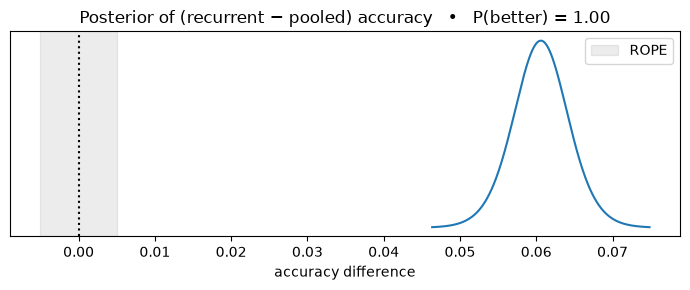

In [58]:
import json, numpy as np
from scipy import stats
import matplotlib.pyplot as plt

pooled = np.array(json.load(open(RESULTS/"axis_final_raw.json"))["COMBINED"])     # 15 folds
recur  = np.array(json.load(open(RESULTS/"axis_rnn_final_raw.json"))["maxpool"])  # 15 folds
assert len(pooled) == len(recur) == 15, "folds must align (seeds 0/3/5 x 5)"

def benavoli(diffs, rope=0.005, rho=0.2):
    d = np.asarray(diffs, float); n = len(d)
    mu, var = d.mean(), d.var(ddof=1)
    scale = np.sqrt(var*(1/n + rho/(1-rho))); df = n-1
    pb = stats.t.sf((rope-mu)/scale, df); pw = stats.t.cdf((-rope-mu)/scale, df)
    return mu, scale, df, pb, max(0,1-pb-pw), pw

mu, scale, df, pb, pr, pw = benavoli(recur - pooled)
print(f"recurrent - pooled: Δ={mu:+.4f}  P(recurrent better)={pb:.3f}  P(rope)={pr:.3f}  P(worse)={pw:.3f}")

xs = np.linspace(mu-4*scale, mu+4*scale, 400)
plt.figure(figsize=(7,3))
plt.plot(xs, stats.t.pdf((xs-mu)/scale, df)/scale)
plt.axvspan(-0.005, 0.005, alpha=0.15, color="gray", label="ROPE")
plt.axvline(0, ls=":", c="k")
plt.title(f"Posterior of (recurrent − pooled) accuracy   •   P(better) = {pb:.2f}")
plt.xlabel("accuracy difference"); plt.yticks([]); plt.legend(); plt.tight_layout(); plt.show()

### three-way comparison + posterior plots

means  sparse=0.6321  pooled=0.6682  recurrent=0.7288

recurrent  vs pooled     Δ=+0.0606  P(better)=1.000  P(rope)=0.000  P(worse)=0.000
pooled     vs sparse     Δ=+0.0361  P(better)=1.000  P(rope)=0.000  P(worse)=0.000
recurrent  vs sparse     Δ=+0.0967  P(better)=1.000  P(rope)=0.000  P(worse)=0.000


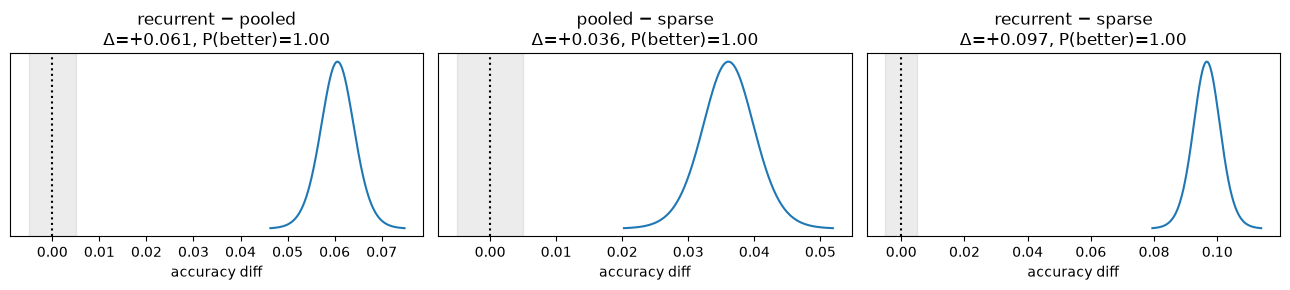

In [61]:
import json, numpy as np
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

P1 = next((p for p in [Path("part1/results"), Path("../part1/results")]
           if (p/"all_results_export_NEW.json").exists()), Path("../part1/results"))

sparse = np.array(json.load(open(P1/"all_results_export_NEW.json"))
                  ["grid_and_extensions"]["mlp1_diffprod"]["all_fold_accuracies"]).ravel()   # 15, seeds 0/3/5 × 5
pooled = np.array(json.load(open(RESULTS/"axis_final_raw.json"))["COMBINED"])
recur  = np.array(json.load(open(RESULTS/"axis_rnn_final_raw.json"))["maxpool"])
assert len(sparse) == len(pooled) == len(recur) == 15   # same folds, same order

def benavoli(diffs, rope=0.005, rho=0.2):
    d = np.asarray(diffs, float); n = len(d); mu = d.mean(); var = d.var(ddof=1)
    sc = np.sqrt(var*(1/n + rho/(1-rho))); df = n-1
    pb = stats.t.sf((rope-mu)/sc, df); pw = stats.t.cdf((-rope-mu)/sc, df)
    return mu, sc, df, pb, max(0, 1-pb-pw), pw

print(f"means  sparse={sparse.mean():.4f}  pooled={pooled.mean():.4f}  recurrent={recur.mean():.4f}\n")
pairs = [("recurrent","pooled",recur,pooled), ("pooled","sparse",pooled,sparse), ("recurrent","sparse",recur,sparse)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (a, b, xa, xb) in zip(axes, pairs):
    mu, sc, df, pb, pr, pw = benavoli(xa - xb)
    print(f"{a:10s} vs {b:9s}  Δ={mu:+.4f}  P(better)={pb:.3f}  P(rope)={pr:.3f}  P(worse)={pw:.3f}")
    xs = np.linspace(mu-4*sc, mu+4*sc, 400)
    ax.plot(xs, stats.t.pdf((xs-mu)/sc, df)/sc)
    ax.axvspan(-0.005, 0.005, alpha=0.15, color="gray"); ax.axvline(0, ls=":", c="k")
    ax.set_title(f"{a} − {b}\nΔ={mu:+.3f}, P(better)={pb:.2f}"); ax.set_yticks([]); ax.set_xlabel("accuracy diff")
plt.tight_layout(); plt.show()

## 6. Search protocol and experimental variance 

### How the search was structured
Two tiers (controlled 40k we will do scaling in Step 7). Fixed 40k working set and fixed folds
(CV seeds [0,3,5] × 5), frozen and shared so every model is paired on identical splits.
**Anchor-and-screen**, one axis at a time: cost is the *sum* of axis sizes (~13/family),
not the product, and each result isolates one choice. Screen on seed 0, then **confirm the
combined configuration on seeds 3/5** — which guards against selecting on one seed, and is
*not* a stack of one-axis winners (Step 5 showed GRU and lr-3e-3 did not survive combination).
Equal budget per family (same #configs, 20 epochs, one device per comparison).

### Why the Benavoli/ROPE test
k-fold CV folds share training data, so accuracies are correlated and a naive paired t-test
is over-confident. We use the Bayesian correlated t-test with the **Nadeau–Bengio** variance
correction (ρ = 1/k = 0.2) and a **ROPE of ±0.005**; decisive at P > 0.95.

### Variance study — two noise sources separated
Fix one fold (data constant) and retrain 5× varying only the init seed → init-seed variance;
compare with the across-fold spread → split variance.

| Model | init-seed std | across-fold std |
|---|---|---|
| pooled | 0.0049 | 0.0043 |
| recurrent | 0.0041 | 0.0051 |

The two are **comparable (≈0.004–0.005); neither dominates.** Three consequences:
1. It **calibrates the ROPE**: the empirical run-to-run noise floor ≈ 0.005, exactly our
   a-priori ROPE — so calling sub-0.005 gaps "equivalent" is justified by the noise, not arbitrary.
2. It **confirms the decisive findings**: max-pooling (+0.031), recurrence (+0.061), the
   embedding effects (±0.06) are all 6–12× the noise floor; the "inconclusive" axes (~0.003)
   were genuinely inside it.
3. It **justifies averaging over 15 runs** (varying both init and split): since init noise is
   not negligible, a single run per config would read seed luck as signal.

### Cross-family comparison — what each capability buys (same 15 folds)

| System | Acc | vs below |
|---|---|---|
| sparse `mlp1_diffprod` | 0.6321 ± 0.0050 | — |
| pooled (meanmax, fine-tuned) | 0.6682 ± 0.0043 | +0.036 |
| recurrent (LSTM-maxpool) | 0.7288 ± 0.0051 | +0.061 |

All pairwise gaps decisive (P(better) ≈ 1.0), all ≫ the 0.005 floor. **Nuance:** the sparse
diffprod baseline is strong — it already uses [u,v,|u−v|,u·v] — and naive mean-pool-frozen
GloVe (0.616) is *worse* than it. Pretrained embeddings beat sparse features only once pooled
well and fine-tuned (+0.036). **Word order (the recurrent jump, +0.061) is the largest single
gain.** Answer to the framing question: pretrained embeddings add modestly and conditionally;
word order adds a lot.

# 7. Scaling study - Full-data learning curve